# Практическая работа 5. Корреляционный анализ (Titanic)

## 1. Загрузка библиотек и данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
import os
if not os.path.exists('titanic.csv'):
    from google.colab import files
    files.upload('titanic.csv')

df = pd.read_csv('titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Выбор признаков и целевой переменной

In [3]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

X = df[features].copy()
y = df[target].copy()
X.head()

,Pclass,Age,Sex,Fare,SibSp,Parch
0,3,22.0,male,7.2500,1,0
1,1,38.0,female,71.2833,1,0
2,3,26.0,female,7.9250,0,0
3,1,35.0,female,53.1000,1,0
4,3,35.0,male,8.0500,0,0


## 3. Пропущенные значения

In [4]:
print('Пропуски в признаках:')
print(X.isna().sum())
print('\nПропуски в целевой переменной:', y.isna().sum())

Пропуски в признаках:
Pclass      0
Age       177
Sex         0
Fare        0
SibSp       0
Parch       0
dtype: int64

Пропуски в целевой переменной: 0


## 4. Обработка пропусков в Age (заполняем медианой)

In [5]:
X['Age'] = X['Age'].fillna(X['Age'].median())
print(X.isna().sum())

Pclass    0
Age       0
Sex       0
Fare      0
SibSp     0
Parch     0
dtype: int64


## 5. Преобразование Sex в числовой вид

In [6]:
X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
print(X['Sex'].value_counts())

print('\nПропусков всего:', X.isna().sum().sum())
print(X.dtypes)

Sex
0    577
1    314
Name: count, dtype: int64

Пропусков всего: 0
Pclass      int64
Age       float64
Sex         int64
Fare      float64
SibSp       int64
Parch       int64
dtype: object


## 6. Таблица для корреляционного анализа

In [7]:
data = X.copy()
data[target] = y

print('Столбцы:', list(data.columns))
print('\nТипы данных:')
print(data.dtypes)
print('\nПропуски:')
print(data.isna().sum())
data.head()

Столбцы: ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']

Типы данных:
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object

Пропуски:
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64


,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,0,7.2500,1,0,0
1,1,38.0,1,71.2833,1,0,1
2,3,26.0,1,7.9250,0,0,1
3,1,35.0,1,53.1000,1,0,1
4,3,35.0,0,8.0500,0,0,0


## 7. Корреляционная матрица (Пирсон)

In [8]:
corr = data.corr(method='pearson').round(2)
corr

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
Pclass,1.00,-0.34,-0.13,-0.55,0.08,0.02,-0.34
Age,-0.34,1.00,-0.08,0.10,-0.23,-0.17,-0.06
Sex,-0.13,-0.08,1.00,0.18,0.11,0.25,0.54
Fare,-0.55,0.10,0.18,1.00,0.16,0.22,0.26
SibSp,0.08,-0.23,0.11,0.16,1.00,0.41,-0.04
Parch,0.02,-0.17,0.25,0.22,0.41,1.00,0.08
Survived,-0.34,-0.06,0.54,0.26,-0.04,0.08,1.00


In [9]:
surv_corr = corr[target].drop(target)
print(surv_corr.sort_values(ascending=False))

print('\nСамая сильная положительная корреляция с Survived:',
      surv_corr.idxmax(), '=', surv_corr.max())
print('Самая сильная отрицательная корреляция с Survived:',
      surv_corr.idxmin(), '=', surv_corr.min())

Sex       0.54
Fare      0.26
Parch     0.08
SibSp    -0.04
Age      -0.06
Pclass   -0.34
Name: Survived, dtype: float64

Самая сильная положительная корреляция с Survived: Sex = 0.54
Самая сильная отрицательная корреляция с Survived: Pclass = -0.34


## 8. Тепловая карта (seaborn.heatmap)

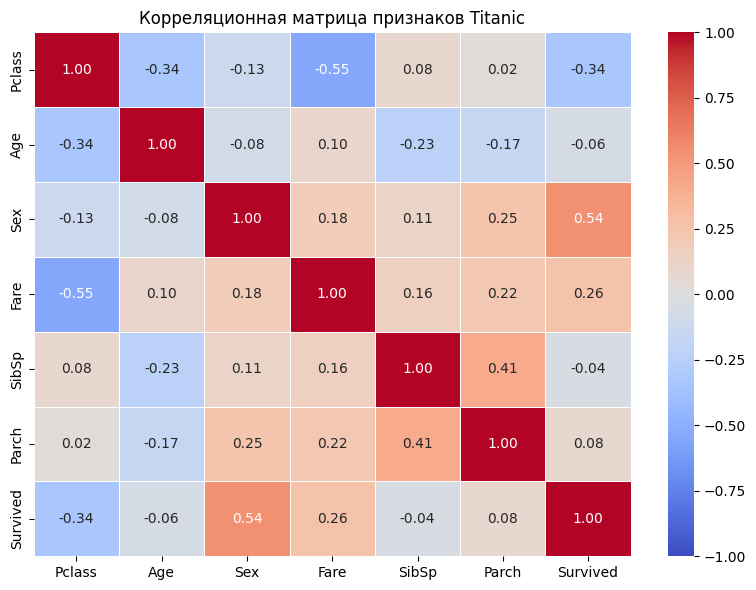

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            vmin=-1, vmax=1,
            linewidths=0.5,
            cbar=True)
plt.title('Корреляционная матрица признаков Titanic')
plt.tight_layout()
plt.show()

## 9. Выводы

**Какие признаки полезны для предсказания Survived?**
Судя по корреляциям, наиболее полезны **Sex** (сильная положительная связь: у женщин (1) выживаемость выше) и **Pclass** (отрицательная связь: чем ниже класс — тем меньше шансов выжить). Также заметна положительная связь с **Fare** (она связана с Pclass: дорогие билеты — высший класс). **Age, SibSp, Parch** связаны с Survived слабо.

*(Проверьте по своей матрице — значения должны совпадать с выводом выше.)*

**Можно ли выбирать признаки для модели только по корреляции?**
Нет. Причины:
- Пирсон измеряет только **линейную** связь; нелинейные зависимости (например, у Age) он может не заметить.
- Признаки могут быть **взаимосвязаны** (Fare и Pclass) и дублировать информацию.
- Признак со слабой парной корреляцией может быть полезен **в комбинации** с другими (взаимодействия).
- Корреляция не доказывает причинности.
- Для бинарной цели и категориальных признаков Пирсон — лишь приближение.

Поэтому корреляцию используют как первичную разведку, а отбор признаков проверяют на модели (качество на валидации, важность признаков и т.д.).